# Welch Procedure — Per-product DQN vs (s,S) — v3 (residual policy)

> **Version 3 (2026-10-28).** Adds phase D, the residual policy on top of the re-tuned (s,S).
> Previous versions: `welch_procedure_product_dqn_v1.ipynb` (reference = original (s,S)),
> `welch_procedure_product_dqn_v2.ipynb` (re-tuned (s,S), phase C, ablation). Log: `docs/experiments/README.md`.

Steady-state analysis of the per-product DQN agents trained on `ProductInventoryEnvironment`
(one controller per product, order-up-to actions, compact observation; see `src/environment/structured_env.py`).

All configurations run on the **same seeds** with common random numbers (`StreamedInventorySimulation`:
same customers and same k-th lead time per product for every policy). Since the two products are independent
(separate suppliers, separate K, separate random streams), the cost of a product does not depend on the policy
of the other one: mixed configurations (DQN on one product, (s,S) on the other) can be read off the per-product breakdown.

| Configuration | Policy per product |
|---|---|
| `(s,S) baseline` | (20, 38) / (19, 37) — original grid search (`notebooks/baseline.ipynb`) |
| `(s,S) tuned` | (25, 30) / (23, 29) — re-tuned with CRN (`scripts/tune_ss_policy.py`) — **reference** |
| `DQN (i·q in reward)` | DQN, reward = −full cost × 1/100 |
| `DQN (no i·q)` | DQN, reward = −(cost − i·q) × 1/100 (phase C); evaluated on the full cost |
| `DQN residual (s,S)` | phase D: each day the DQN picks a correction (δs, δS) ∈ {−3..3}² of the tuned (s,S); same reward as phase C |

Section 8 shows what the residual agent does differently from the (s,S); section 10 reports the ablation: DQN on the original joint `InventoryEnvironment` with the same hyperparameters and reward scale.

## Setup & Imports

In [1]:
import sys

sys.path.insert(0, "..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from stable_baselines3 import DQN

from src.agents.metrics import EvaluationMetrics
from src.agents.metrics.joint_evaluation import (
    compare_joint_policies,
    format_comparison,
    run_joint_episode,
    summarize_comparison,
)
from src.environment import FrameStackJointPolicy, ModelProductPolicy, ProductPolicy, SSProductPolicy
from src.seeds import generate_seeds

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

## Configuration

In [2]:
ROOT = Path("..")

SIM_DAYS = 1000  # Days per replication (about 3 years)
NUM_REPLICATIONS = 300  # Independent runs
WINDOW_SIZE = 25  # Half-width of the Welch moving average
ABLATION_REPLICATIONS = 30  # Joint-env ablation (much worse, fewer seeds suffice)

# Test seeds; (s,S) tuning used seeds 300-499 and DQN validation seeds 900+ (disjoint)
WELCH_SEEDS = generate_seeds(NUM_REPLICATIONS, start_index=0)
VALIDATION_SEEDS = generate_seeds(10, start_index=900)

REFERENCE = "(s,S) tuned"

# Candidate training runs per DQN variant and product: the `best` checkpoint of each
# run is re-evaluated on the same validation seeds and the lowest-cost one is used
DQN_VARIANTS = {
    "DQN (i·q in reward)": {
        0: ["dqn_p0_rs100_1M", "dqn_p0_rs100_s1234_1M"],
        1: ["dqn_p1_rs100_1M", "dqn_p1_rs100_s1234_1M"],
    },
    "DQN (no i·q)": {
        0: ["dqn_p0_rs100_noiq_1M", "dqn_p0_rs100_noiq_s1234_1M"],
        1: ["dqn_p1_rs100_noiq_1M", "dqn_p1_rs100_noiq_s1234_1M"],
    },
    "DQN residual (s,S)": {
        0: ["dqn_p0_residual_1M", "dqn_p0_residual_s1234_1M"],
        1: ["dqn_p1_residual_1M", "dqn_p1_residual_s1234_1M"],
    },
}
JOINT_ABLATION_DIR = ROOT / "models/dqn_joint_rs0.01_1M/best"

# Categorical colors, fixed order (one per configuration, never cycled)
COLORS = {
    "(s,S) baseline": "#2a78d6",
    "(s,S) tuned": "#eb6834",
    "DQN (i·q in reward)": "#1baf7a",
    "DQN (no i·q)": "#eda100",
    "DQN residual (s,S)": "#e87ba4",
}

print(f"📋 Simulation: {SIM_DAYS} days × {NUM_REPLICATIONS} replications")
print(f"   Smoothing window: {WINDOW_SIZE} days, reference: {REFERENCE}")

📋 Simulation: 1000 days × 300 replications
   Smoothing window: 25 days, reference: (s,S) tuned


## Policies

In [3]:
def validation_cost(policy: ModelProductPolicy) -> float:
    """Steady-state cost of the product on the validation seeds (partner: tuned (s,S))."""
    pid = policy.product_id
    pair = (policy, SSProductPolicy.tuned(1)) if pid == 0 else (SSProductPolicy.tuned(0), policy)
    return float(np.mean([run_joint_episode(pair, s, SIM_DAYS)[f"cost_{pid}"][200:].mean() for s in VALIDATION_SEEDS]))


def best_run(run_names: list[str]) -> Path | None:
    """Best checkpoint among the available runs, re-evaluated on the same validation seeds."""
    candidates = []
    for name in run_names:
        path = ROOT / "models" / name / "best"
        if (path / "dqn_model.zip").exists():
            meta = json.loads((path / "dqn_model_metadata.json").read_text())
            cost = validation_cost(ModelProductPolicy.load(path))
            candidates.append((cost, path))
            print(f"   {name:<28} checkpoint @ {meta['timesteps']:>9,} steps | validation ${cost:.2f}/day")
    if not candidates:
        return None
    cost, path = min(candidates, key=lambda c: c[0])
    print(f"   -> {path.parent.name}")
    return path


CONFIGS = {
    "(s,S) baseline": (SSProductPolicy.baseline(0), SSProductPolicy.baseline(1)),
    "(s,S) tuned": (SSProductPolicy.tuned(0), SSProductPolicy.tuned(1)),
}
for variant, runs in DQN_VARIANTS.items():
    print(variant)
    paths = {pid: best_run(names) for pid, names in runs.items()}
    if all(paths.values()):
        CONFIGS[variant] = tuple(
            ModelProductPolicy.load(paths[pid], label=f"{variant} P{pid}") for pid in (0, 1)
        )

NAMES = list(CONFIGS)

DQN (i·q in reward)


   dqn_p0_rs100_1M              checkpoint @   400,000 steps | validation $18.83/day


   dqn_p0_rs100_s1234_1M        checkpoint @   250,000 steps | validation $19.38/day
   -> dqn_p0_rs100_1M


   dqn_p1_rs100_1M              checkpoint @   450,000 steps | validation $21.47/day


   dqn_p1_rs100_s1234_1M        checkpoint @   500,000 steps | validation $20.82/day
   -> dqn_p1_rs100_s1234_1M
DQN (no i·q)


...

   dqn_p1_rs100_noiq_s1234_1M   checkpoint @   950,000 steps | validation $20.99/day
   -> dqn_p1_rs100_noiq_1M
DQN residual (s,S)


   dqn_p0_residual_1M           checkpoint @   750,000 steps | validation $17.55/day


   dqn_p0_residual_s1234_1M     checkpoint @   550,000 steps | validation $17.86/day
   -> dqn_p0_residual_1M


   dqn_p1_residual_1M           checkpoint @   850,000 steps | validation $20.43/day


   dqn_p1_residual_s1234_1M     checkpoint @   250,000 steps | validation $20.48/day
   -> dqn_p1_residual_1M


## 1. Simulation (common random numbers)

In [4]:
_, episodes = compare_joint_policies(CONFIGS, WELCH_SEEDS, episode_length=SIM_DAYS, reference=REFERENCE)

Evaluating (s,S) baseline on 300 seeds...


Evaluating (s,S) tuned on 300 seeds...


Evaluating DQN (i·q in reward) on 300 seeds...


Evaluating DQN (no i·q) on 300 seeds...


Evaluating DQN residual (s,S) on 300 seeds...


## 2. Average Daily Cost Across Replications

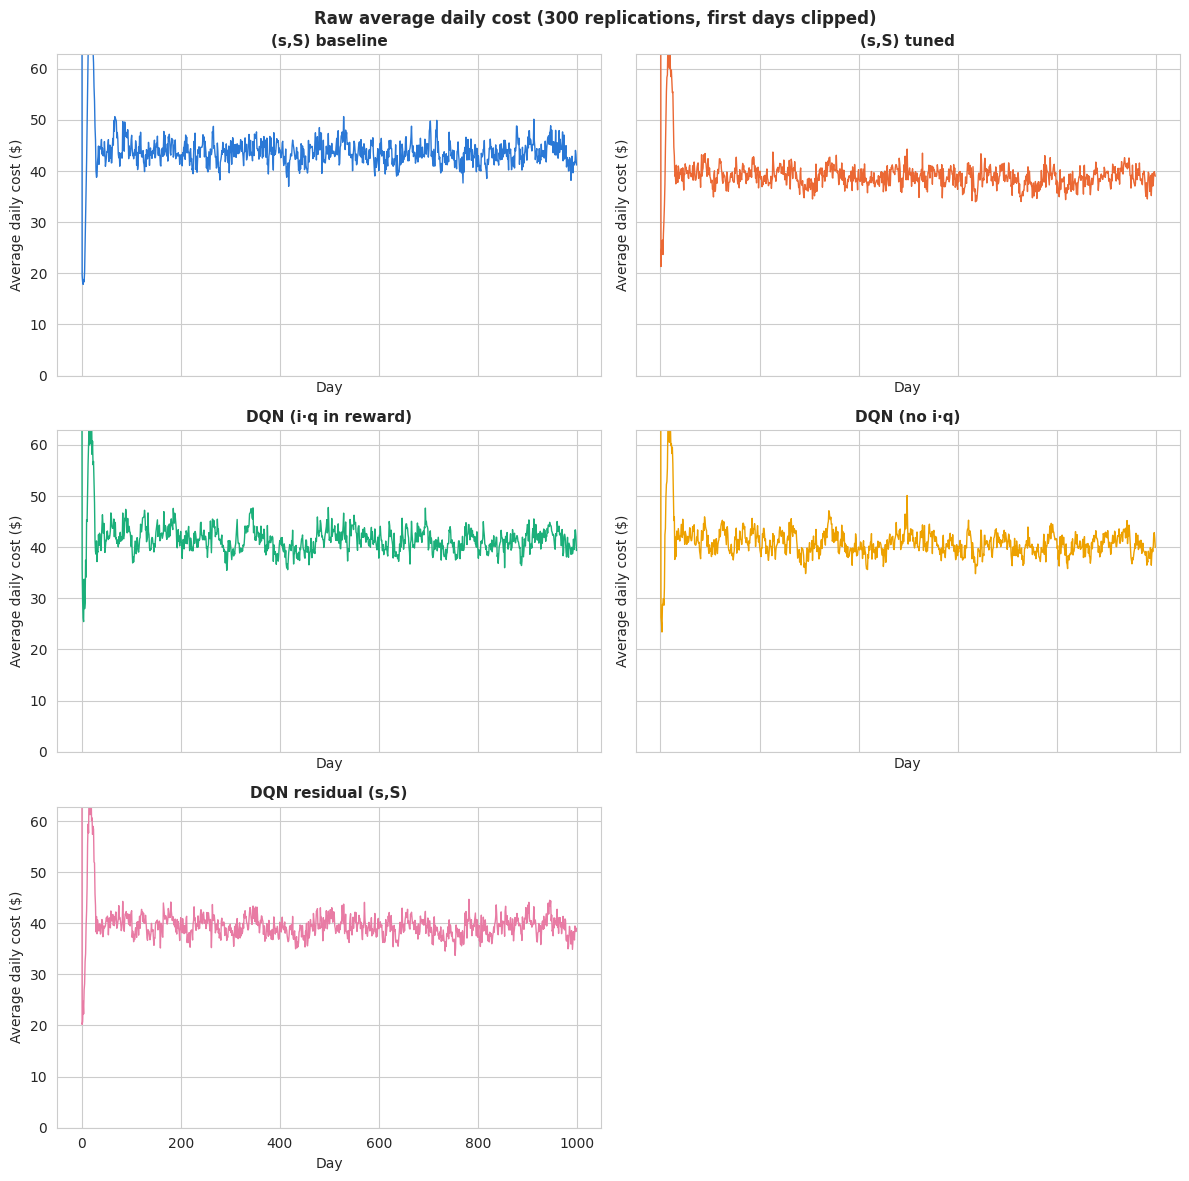

In [5]:
avg_daily = {
    name: np.mean([ep["total_daily_cost"] for ep in eps], axis=0)
    for name, eps in episodes.items()
}

nrows = int(np.ceil(len(avg_daily) / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(12, 4 * nrows), sharex=True, sharey=True)
for ax in axes.flat[len(avg_daily) :]:
    ax.set_visible(False)
for ax, (name, y) in zip(axes.flat, avg_daily.items()):
    ax.plot(y, linewidth=1, color=COLORS[name])
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.set_xlabel("Day")
    ax.set_ylabel("Average daily cost ($)")
    ax.set_ylim(0, 1.6 * np.mean(y[len(y) // 2 :]))
fig.suptitle(
    f"Raw average daily cost ({NUM_REPLICATIONS} replications, first days clipped)",
    fontweight="bold",
)
plt.tight_layout()
plt.show()

## 3. Welch's Smoothing and Warmup Detection

Same plateau rule as `welch_procedure.ipynb`: first day after which a 50-day window stays within 5% of the second-half mean.

Note: the search starts at day 50, so 50 is the smallest warmup the rule can return. The y-axis of the plots is clipped: the first days (empty pipeline) cost much more.

In [6]:
def detect_warmup_length(smoothed_data: list[float], tolerance: float = 0.05) -> int:
    """First day after which the smoothed curve stays within `tolerance` of the steady-state mean."""
    if len(smoothed_data) < 100:
        return len(smoothed_data) // 2

    steady_state_mean = np.mean(smoothed_data[len(smoothed_data) // 2 :])
    threshold = tolerance * steady_state_mean
    for i in range(50, len(smoothed_data) - 50):
        if all(abs(v - steady_state_mean) <= threshold for v in smoothed_data[i : i + 50]):
            return i
    return len(smoothed_data) // 2


smoothed = {
    name: EvaluationMetrics()._compute_moving_average(list(y), WINDOW_SIZE)
    for name, y in avg_daily.items()
}
warmups = {name: detect_warmup_length(s) for name, s in smoothed.items()}

# One common warmup for all configurations keeps the comparison paired
WARMUP = max(warmups.values())

print("🔍 Detected warmup lengths:")
for name, w in warmups.items():
    print(f"   {name:<22} {w} days")
print(f"\n➡️  Common warmup used for the comparison: {WARMUP} days")

🔍 Detected warmup lengths:
   (s,S) baseline         50 days
   (s,S) tuned            50 days
   DQN (i·q in reward)    50 days
   DQN (no i·q)           51 days
   DQN residual (s,S)     50 days

➡️  Common warmup used for the comparison: 51 days


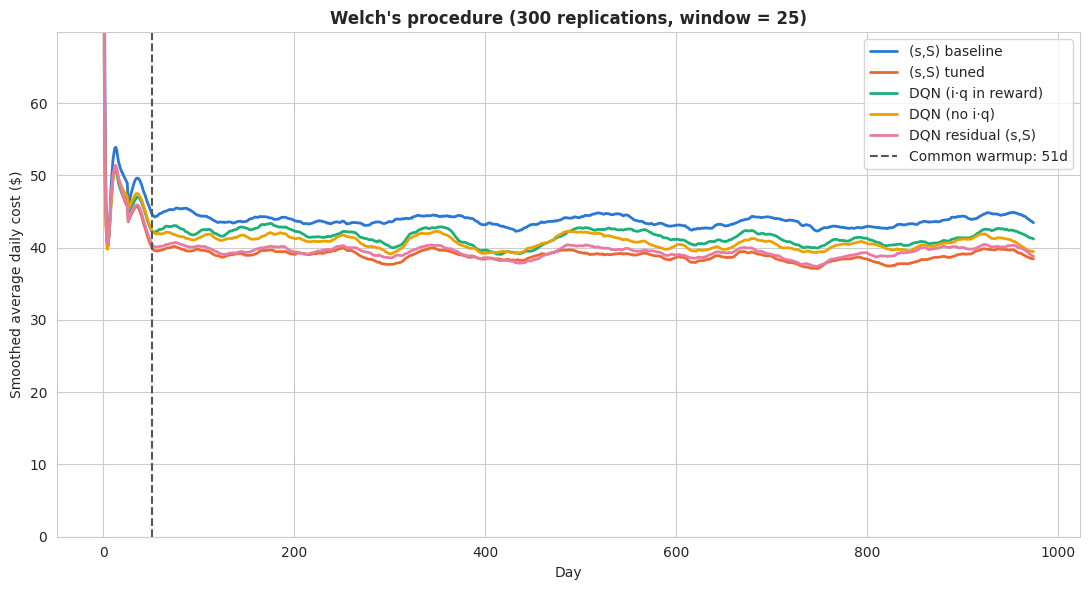

In [7]:
Y_TOP = 1.6 * max(np.mean(s[len(s) // 2 :]) for s in smoothed.values())

fig, ax = plt.subplots(figsize=(11, 6))
for name, s in smoothed.items():
    ax.plot(s, label=name, linewidth=2, color=COLORS[name])
ax.axvline(WARMUP, color="#555", linestyle="--", linewidth=1.5, label=f"Common warmup: {WARMUP}d")
ax.set_ylim(0, Y_TOP)
ax.set_xlabel("Day")
ax.set_ylabel("Smoothed average daily cost ($)")
ax.set_title(
    f"Welch's procedure ({NUM_REPLICATIONS} replications, window = {WINDOW_SIZE})",
    fontweight="bold",
)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Steady-State Comparison

CI95 = Student-t over replications. **Δ vs ref** is the paired difference per seed against `(s,S) tuned` (common random numbers), so its CI is much tighter than the unpaired ones.

In [8]:
table = summarize_comparison(episodes, warmup=WARMUP, reference=REFERENCE)
display(Markdown(format_comparison(table)))

| Policy | $/day ± CI95 | Δ vs ref ± CI95 | P0 $/day (ord/hold/short) | P1 $/day (ord/hold/short) | Fill rate P0/P1 | No-stockout days P0/P1 |
|---|---|---|---|---|---|---|
| (s,S) baseline | 43.70 ± 0.36 | +4.85 ± 0.25 | 20.10 (2.9/11.8/5.3) | 23.61 (4.2/13.5/5.9) | 83.3% / 83.2% | 87.4% / 87.9% |
| (s,S) tuned | 38.86 ± 0.34 | +0.00 ± 0.00 | 17.91 (3.8/10.0/4.1) | 20.94 (5.1/11.1/4.8) | 84.0% / 83.2% | 88.8% / 88.5% |
| DQN (i·q in reward) | 41.47 ± 0.51 | +2.61 ± 0.29 | 19.71 (4.1/7.7/8.0) | 21.75 (6.4/8.5/6.9) | 73.9% / 76.2% | 80.7% / 83.6% |
| DQN (no i·q) | 40.69 ± 0.44 | +1.84 ± 0.24 | 19.23 (4.5/7.9/6.8) | 21.47 (6.2/9.1/6.1) | 76.1% / 78.0% | 82.6% / 85.0% |
| DQN residual (s,S) | 39.37 ± 0.38 | +0.52 ± 0.16 | 18.10 (3.7/10.1/4.3) | 21.27 (5.1/10.4/5.8) | 83.7% / 80.4% | 88.4% / 86.4% |

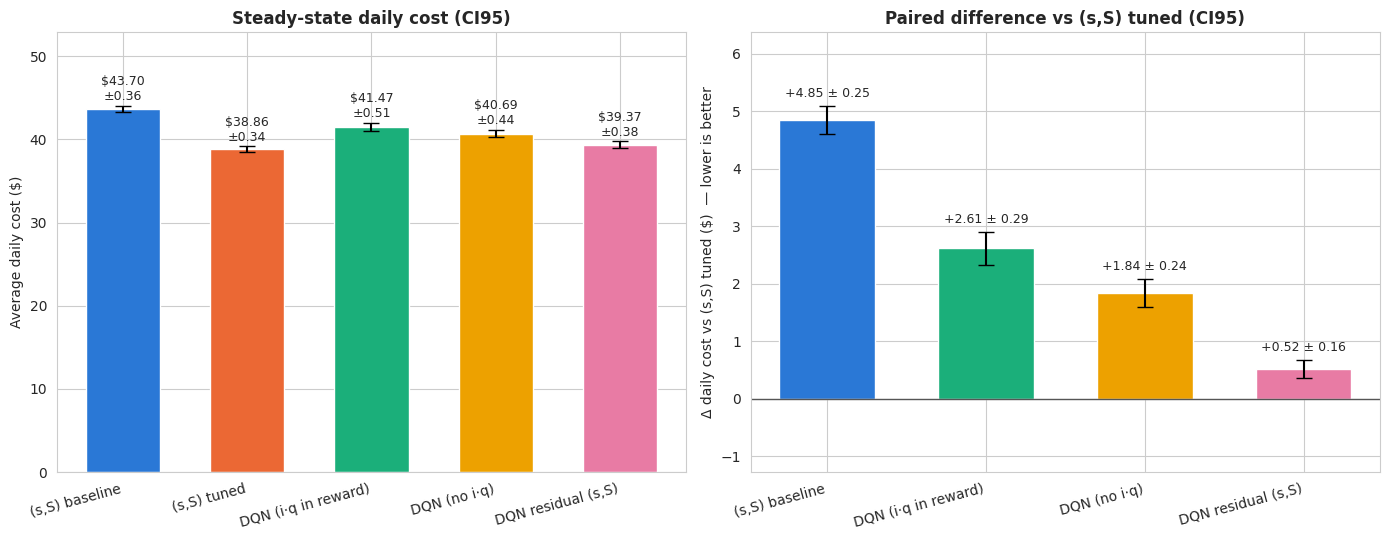

In [9]:
x = np.arange(len(NAMES))
colors = [COLORS[n] for n in NAMES]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
ax.bar(x, table["cost_mean"], yerr=table["cost_ci"], capsize=6, color=colors, width=0.6)
for i, (m, c) in enumerate(zip(table["cost_mean"], table["cost_ci"])):
    ax.text(i, m + c + 0.3, f"${m:.2f}\n±{c:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x, NAMES, rotation=15, ha="right")
ax.set_ylabel("Average daily cost ($)")
ax.set_title("Steady-state daily cost (CI95)", fontweight="bold")
ax.set_ylim(0, (table["cost_mean"] + table["cost_ci"]).max() * 1.2)

ax = axes[1]
diff = table.drop(index=REFERENCE)
xd = np.arange(len(diff))
ax.bar(xd, diff["diff_vs_ref_mean"], yerr=diff["diff_vs_ref_ci"], capsize=6,
       color=[COLORS[n] for n in diff.index], width=0.6)
ax.axhline(0, color="#555", linewidth=1)
lo = (diff["diff_vs_ref_mean"] - diff["diff_vs_ref_ci"]).min()
hi = (diff["diff_vs_ref_mean"] + diff["diff_vs_ref_ci"]).max()
pad = 0.25 * (max(hi, 0) - min(lo, 0))
ax.set_ylim(min(lo, 0) - pad, max(hi, 0) + pad)
for i, (m, c) in enumerate(zip(diff["diff_vs_ref_mean"], diff["diff_vs_ref_ci"])):
    ax.text(i, m + (c + 0.1) * (1 if m >= 0 else -1), f"{m:+.2f} ± {c:.2f}",
            ha="center", va="bottom" if m >= 0 else "top", fontsize=9)
ax.set_xticks(xd, diff.index, rotation=15, ha="right")
ax.set_ylabel(f"Δ daily cost vs {REFERENCE} ($)  — lower is better")
ax.set_title(f"Paired difference vs {REFERENCE} (CI95)", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Cost Breakdown per Product

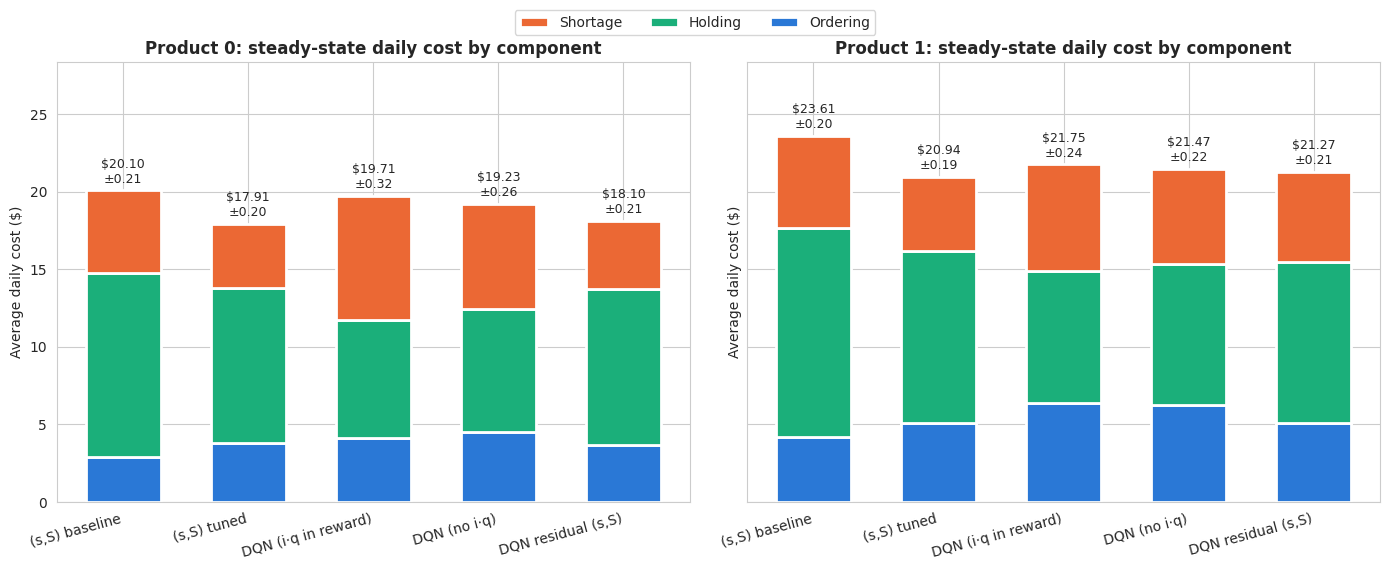

In [10]:
components = ["ordering", "holding", "shortage"]
comp_colors = {"ordering": "#2a78d6", "holding": "#1baf7a", "shortage": "#eb6834"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for j, ax in enumerate(axes):
    bottom = np.zeros(len(NAMES))
    for comp in components:
        vals = table[f"p{j}_{comp}"].to_numpy()
        ax.bar(x, vals, bottom=bottom, color=comp_colors[comp], width=0.6,
               edgecolor="white", linewidth=2, label=comp.capitalize())
        bottom += vals
    for i, (total, ci) in enumerate(zip(bottom, table[f"p{j}_cost_ci"])):
        ax.text(i, total + 0.3, f"${total:.2f}\n±{ci:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_xticks(x, NAMES, rotation=15, ha="right")
    ax.set_title(f"Product {j}: steady-state daily cost by component", fontweight="bold")
    ax.set_ylabel("Average daily cost ($)")
    ax.set_ylim(0, bottom.max() * 1.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles[::-1], labels[::-1], loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

## 6. Service Level per Product

- **Fill rate**: units served immediately from stock / units demanded
- **No-stockout days**: fraction of days ending without backorders

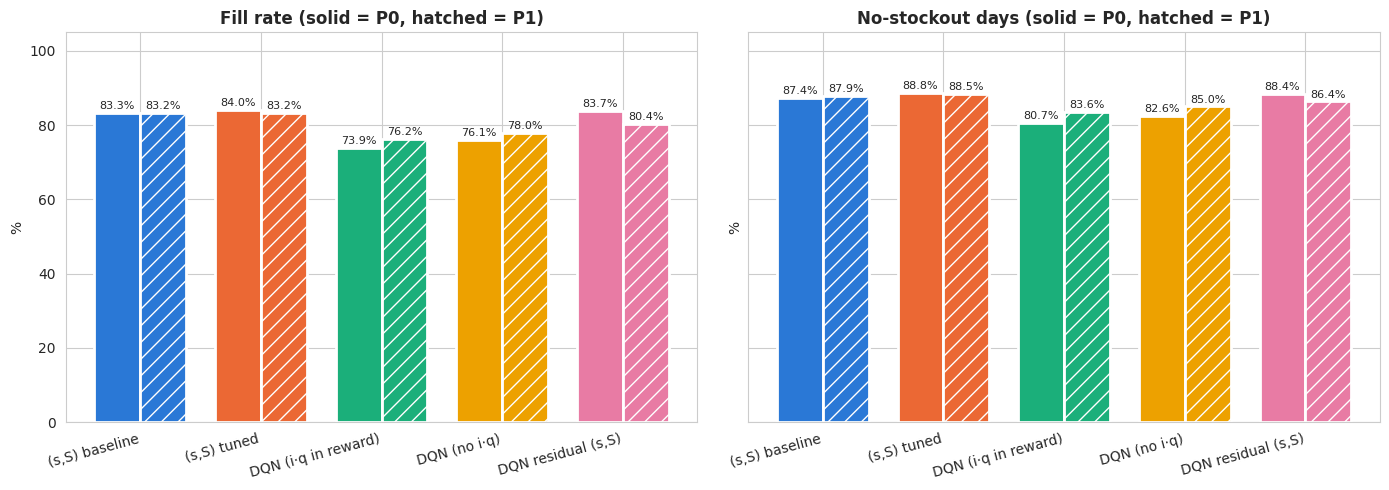

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
width = 0.38
for ax, (metric, title) in zip(axes, [("fill_rate", "Fill rate"), ("no_stockout", "No-stockout days")]):
    for j, offset in ((0, -width / 2), (1, width / 2)):
        vals = table[f"p{j}_{metric}"].to_numpy() * 100
        bars = ax.bar(x + offset, vals, width=width, color=colors, edgecolor="white", linewidth=2,
                      hatch=None if j == 0 else "//")
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x, NAMES, rotation=15, ha="right")
    ax.set_ylim(0, 105)
    ax.set_ylabel("%")
    ax.set_title(f"{title} (solid = P0, hatched = P1)", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Inventory Position and Net Inventory (steady state)

An (s,S) policy keeps the inventory position in [s, S] after each decision; the width of the DQN distribution shows how far it is from a stationary threshold rule.

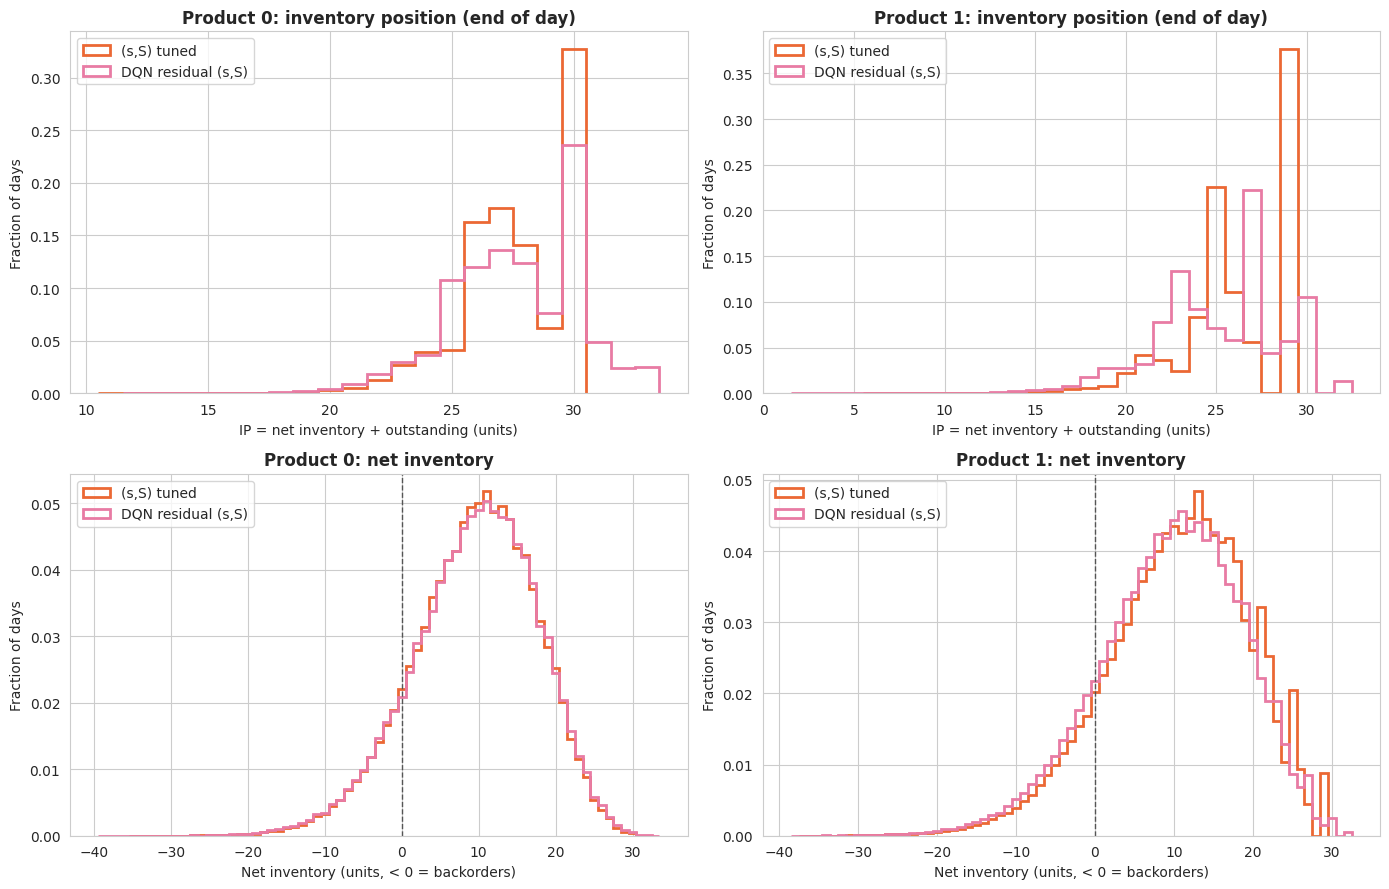

In [12]:
best_dqn = min((n for n in NAMES if n.startswith("DQN")), key=lambda n: table.loc[n, "cost_mean"], default=None)
shown = [n for n in ["(s,S) tuned", best_dqn] if n is not None]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for j in range(2):
    for name in shown:
        eps = episodes[name]
        ip = np.concatenate([ep[f"net_inv_{j}"][WARMUP:] + ep[f"outstanding_{j}"][WARMUP:] for ep in eps])
        inv = np.concatenate([ep[f"net_inv_{j}"][WARMUP:] for ep in eps])
        for ax, data in ((axes[0, j], ip), (axes[1, j], inv)):
            ax.hist(data, bins=np.arange(data.min(), data.max() + 2) - 0.5, density=True,
                    histtype="step", linewidth=2, color=COLORS[name], label=name)
    axes[0, j].set_title(f"Product {j}: inventory position (end of day)", fontweight="bold")
    axes[0, j].set_xlabel("IP = net inventory + outstanding (units)")
    axes[1, j].set_title(f"Product {j}: net inventory", fontweight="bold")
    axes[1, j].set_xlabel("Net inventory (units, < 0 = backorders)")
    axes[1, j].axvline(0, color="#555", linestyle="--", linewidth=1)
    for ax in axes[:, j]:
        ax.set_ylabel("Fraction of days")
        ax.legend()
plt.tight_layout()
plt.show()

## 8. What the Residual Agent Does

For the residual agent: frequency of each correction (δs, δS) chosen in steady state, and how often its
decision differs from the tuned (s,S) on the same state (order vs no order, or a different quantity).

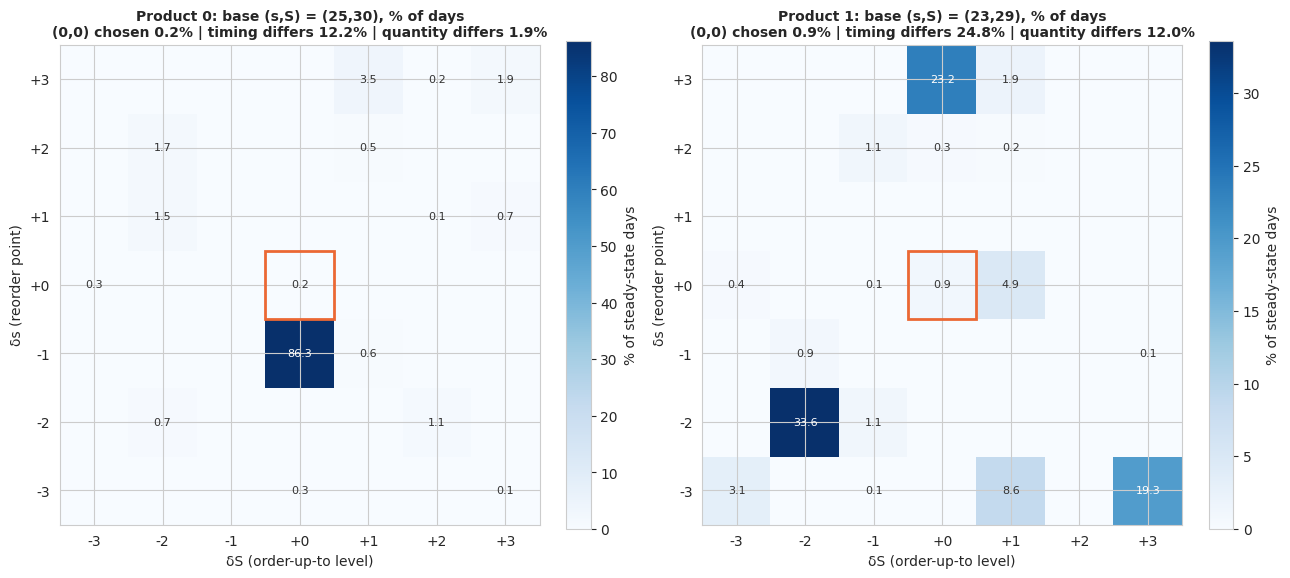

In [13]:
RESIDUAL = "DQN residual (s,S)"
ANALYSIS_SEEDS = WELCH_SEEDS[:30]


class DecisionRecorder(ProductPolicy):
    """Wraps a residual policy and records its actions next to the base (s,S) decision."""

    def __init__(self, policy: ModelProductPolicy, base: SSProductPolicy, warmup: int):
        self.policy, self.base, self.warmup = policy, base, warmup
        self.product_id = policy.product_id
        self.actions, self.q, self.q_base = [], [], []
        self.day = 0

    def reset(self) -> None:
        self.policy.reset()
        self.day = 0

    def act(self, state) -> int:
        q = self.policy.act(state)
        if self.day >= self.warmup:
            self.actions.append(self.policy.last_action)
            self.q.append(q)
            self.q_base.append(self.base.act(state))
        self.day += 1
        return q


if RESIDUAL in CONFIGS:
    fig, axes = plt.subplots(1, 2, figsize=(13, 6))
    for j, ax in enumerate(axes):
        rec = DecisionRecorder(CONFIGS[RESIDUAL][j], SSProductPolicy.tuned(j), WARMUP)
        partner = SSProductPolicy.tuned(1 - j)
        for seed in ANALYSIS_SEEDS:
            run_joint_episode((rec, partner) if j == 0 else (partner, rec), seed, SIM_DAYS)

        spec = rec.policy.spec
        k, width = spec.max_delta, 2 * spec.max_delta + 1
        freq = np.zeros((width, width))
        for a in rec.actions:
            ds, dS = spec.residual(a)
            freq[ds + k, dS + k] += 1
        freq = 100 * freq / freq.sum()
        q, qb = np.array(rec.q), np.array(rec.q_base)
        timing = np.mean((q > 0) != (qb > 0)) * 100
        quantity = np.mean((q > 0) & (qb > 0) & (q != qb)) * 100

        im = ax.imshow(freq, cmap="Blues", origin="lower")
        for (r, c), v in np.ndenumerate(freq):
            if v >= 0.05:
                ax.text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=8,
                        color="white" if v > freq.max() / 2 else "#333")
        ax.add_patch(plt.Rectangle((k - 0.5, k - 0.5), 1, 1, fill=False, edgecolor="#eb6834", linewidth=2))
        ticks = np.arange(width)
        ax.set_xticks(ticks, [f"{d:+d}" for d in range(-k, k + 1)])
        ax.set_yticks(ticks, [f"{d:+d}" for d in range(-k, k + 1)])
        ax.set_xlabel("δS (order-up-to level)")
        ax.set_ylabel("δs (reorder point)")
        s0, S0 = spec.residual_base
        ax.set_title(
            f"Product {j}: base (s,S) = ({s0},{S0}), % of days\n"
            f"(0,0) chosen {freq[k, k]:.1f}% | timing differs {timing:.1f}% | quantity differs {quantity:.1f}%",
            fontweight="bold", fontsize=10,
        )
        fig.colorbar(im, ax=ax, fraction=0.046, label="% of steady-state days")
    plt.tight_layout()
    plt.show()
else:
    print("Residual models not found")

## 9. Training Curves

Greedy policy evaluated every 50k steps on the validation seeds (disjoint from the test seeds), cost of the controlled product only. The first i·q run (seed 6173) used 5 validation seeds, all other runs 10; dashed lines: both (s,S) on the same 10 validation seeds.

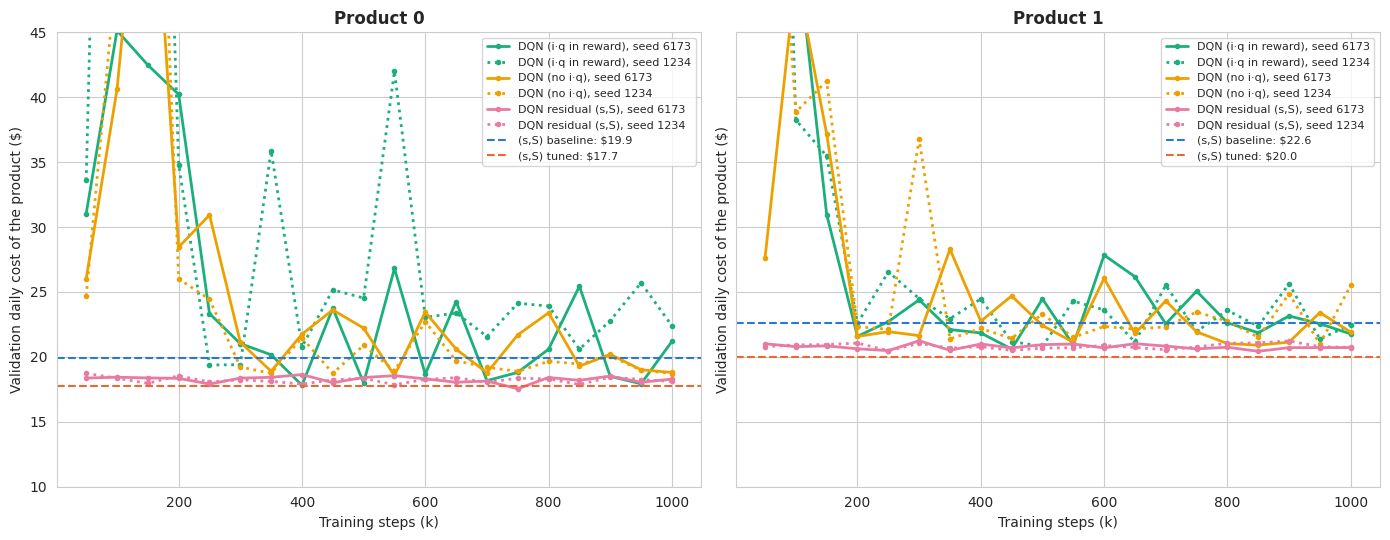

In [14]:
ss_val = {
    name: [run_joint_episode(CONFIGS[name], seed, SIM_DAYS) for seed in VALIDATION_SEEDS]
    for name in ["(s,S) baseline", "(s,S) tuned"]
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
for j, ax in enumerate(axes):
    for variant, runs in DQN_VARIANTS.items():
        for run in runs[j]:
            path = ROOT / "models" / run / "eval_history.json"
            if not path.exists():
                continue
            hist = json.loads(path.read_text())
            seed_tag = "seed 1234" if "s1234" in run else "seed 6173"
            ax.plot([r["timesteps"] / 1e3 for r in hist], [r["product_cost"] for r in hist],
                    linestyle=":" if "s1234" in run else "-", marker="o", markersize=3, linewidth=2,
                    color=COLORS[variant], label=f"{variant}, {seed_tag}")
    for name, eps in ss_val.items():
        ref = np.mean([ep[f"cost_{j}"][200:].mean() for ep in eps])
        ax.axhline(ref, color=COLORS[name], linestyle="--", linewidth=1.5, label=f"{name}: ${ref:.1f}")
    ax.set_ylim(10, 45)
    ax.set_xlabel("Training steps (k)")
    ax.set_ylabel("Validation daily cost of the product ($)")
    ax.set_title(f"Product {j}", fontweight="bold")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Ablation: DQN on the original joint environment

Same hyperparameters and reward scale (×1/100) as the per-product agents, but the original problem structure
(joint quantity action `Discrete(961)`, 31 stacked raw frames, no observation scaling). Evaluated through
`FrameStackJointPolicy`, which rebuilds the original observation and reproduces the original environment's decisions.

In [15]:
if JOINT_ABLATION_DIR.exists():
    meta = json.loads((JOINT_ABLATION_DIR / "dqn_model_metadata.json").read_text())
    joint = FrameStackJointPolicy(
        DQN.load(JOINT_ABLATION_DIR / "dqn_model", device="cpu"), k=meta["k"], Q_max=meta["Q_max"]
    ).as_product_policies(label="Joint DQN (original env)")
    ablation_seeds = WELCH_SEEDS[:ABLATION_REPLICATIONS]
    abl_eps = {
        "(s,S) tuned": episodes["(s,S) tuned"][:ABLATION_REPLICATIONS],
        "Joint DQN (original env)": [run_joint_episode(joint, s, SIM_DAYS) for s in ablation_seeds],
    }
    print(f"Checkpoint @ {meta['timesteps']:,} steps, reward scale {meta['reward_scale']}, "
          f"{ABLATION_REPLICATIONS} replications")
    display(Markdown(format_comparison(summarize_comparison(abl_eps, warmup=WARMUP, reference="(s,S) tuned"))))
else:
    print(f"Ablation model not found: {JOINT_ABLATION_DIR}")

Checkpoint @ 400,000 steps, reward scale 0.01, 30 replications


| Policy | $/day ± CI95 | Δ vs ref ± CI95 | P0 $/day (ord/hold/short) | P1 $/day (ord/hold/short) | Fill rate P0/P1 | No-stockout days P0/P1 |
|---|---|---|---|---|---|---|
| (s,S) tuned | 39.05 ± 1.23 | +0.00 ± 0.00 | 18.08 (3.8/10.0/4.2) | 20.97 (5.1/11.1/4.8) | 83.9% / 83.5% | 88.7% / 88.6% |
| Joint DQN (original env) | 5622.85 ± 221.57 | +5583.81 ± 221.53 | 2690.85 (20.5/2670.3/0.0) | 2932.01 (20.7/2911.3/0.0) | 100.0% / 100.0% | 100.0% / 100.0% |

## 11. Export Results

In [16]:
export_data = {
    "configuration": {
        "sim_days": SIM_DAYS,
        "num_replications": NUM_REPLICATIONS,
        "window_size": WINDOW_SIZE,
        "warmup_days": int(WARMUP),
        "detected_warmups": {k: int(v) for k, v in warmups.items()},
        "reference": REFERENCE,
        "seeds": [int(s) for s in WELCH_SEEDS],
    },
    "results": json.loads(table.to_json(orient="index")),
}

results_dir = ROOT / "results"
results_dir.mkdir(exist_ok=True)
output_path = results_dir / "welch_procedure_product_dqn_v3_results.json"
output_path.write_text(json.dumps(export_data, indent=2))
print(f"✅ Results saved to: {output_path}")

✅ Results saved to: ../results/welch_procedure_product_dqn_v3_results.json
